# NumCompute-Stream demo

A decision-tree-based streaming learning framework built with **NumPy and matplotlib only**.
This notebook follows the four things the demo has to show:

| Step | What happens | Module |
|---|---|---|
| 1 | Load a dataset from a CSV file | `io.py` |
| 2 | Split it into chunks to simulate a stream | `stream.iter_chunks` |
| 3 | Train a pipeline incrementally with `.partial_fit()` on each chunk | `pipeline.py`, `preprocessing.py`, `tree.py`, `stream.py` |
| 4 | Log and visualise metrics over time | `metrics.py`, `stats.py`, `visualise.py` |

### How to run
1. Clone or download the repository and open this notebook from the `demo/` folder (or the repository root).
2. `Kernel > Restart & Run All`. It takes a few seconds.

**No installation, internet access or GitHub token is needed**: the first cell adds your local checkout to
Python's import path. (If you prefer, `pip install -e .` from the repository root works too, and the first
cell then simply finds the installed package.)

## 0. Setup: use the local checkout

In [ ]:
import os
import sys

# Find the repository root: the folder that contains the numcompute_stream package.
here = os.path.abspath(os.getcwd())
ROOT = next((p for p in (here, os.path.dirname(here))
             if os.path.isdir(os.path.join(p, "numcompute_stream"))), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or its demo/ folder.")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

%matplotlib inline
import numpy as np
import matplotlib

import numcompute_stream as ncs
from numcompute_stream import io, metrics, stats, visualise
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.stream import StreamTrainer, iter_chunks
from numcompute_stream.tree import DecisionTreeClassifier

print("numcompute_stream", ncs.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__)
print("package loaded from:", os.path.relpath(os.path.dirname(ncs.__file__), ROOT))

numcompute_stream 0.2.0 | numpy 2.5.3 | matplotlib 3.11.2
package loaded from: numcompute_stream


## 1. Load the dataset with `io.py`

`load_mixed_csv` returns the numeric columns as a float array and the text columns as a string array,
with the rows lined up. The file is the classic Iris dataset (150 flowers, 4 measurements, 3 species).

In [2]:
DATA = os.path.join(ROOT, "demo", "data", "iris.csv")
X, text, names = io.load_mixed_csv(DATA, numeric_cols=(0, 1, 2, 3), header=True)
y = text[:, 0]
feature_names = names[:4]

print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)
print("features:", feature_names)
print("classes :", dict(zip(*[a.tolist() for a in np.unique(y, return_counts=True)])))
print("first rows:\n", X[:3], y[:3])

X: (150, 4) float64 | y: (150,) <U10
features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
classes : {'setosa': 50, 'versicolor': 50, 'virginica': 50}
first rows:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]] ['setosa' 'setosa' 'setosa']


## 2. Simulate a stream

Real streams are messy, so 4% of the cells are blanked (NaN) to give the `Imputer` something to do.
The file is sorted by species, so the rows are shuffled (with a seed) before being cut into chunks of 10;
otherwise the first chunks would contain a single class.

In [3]:
SEED, CHUNK_SIZE = 0, 10
rng = np.random.default_rng(SEED)
X = X.copy()
gaps = rng.random(X.shape) < 0.04
X[gaps] = np.nan

def stream():
    """A fresh pass over the same shuffled stream."""
    return iter_chunks(X, y, chunk_size=CHUNK_SIZE, shuffle=True, seed=SEED)

sizes = [len(y_chunk) for _, y_chunk in stream()]
print(f"{int(gaps.sum())} missing cells injected")
print(f"{len(sizes)} chunks, sizes {sizes}")
X_first, y_first = next(iter(stream()))
print("first chunk labels:", y_first.tolist())

17 missing cells injected
15 chunks, sizes [10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
first chunk labels: ['versicolor', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica', 'virginica', 'setosa']


### Streaming statistics: `update_stats(X_chunk)`

Mean and variance are merged chunk by chunk (Welford / Chan), quantiles come from a reservoir sample.
After the last chunk they must agree with the batch values computed on all the data at once.

In [4]:
state = None
for X_chunk, _ in stream():
    state = stats.update_stats(X_chunk, state)        # one call per chunk
summary = state.result()

print(f"{'feature':<14}{'count':>6}{'mean':>9}{'std':>8}{'min':>6}{'median':>8}{'max':>6}")
for j, name in enumerate(feature_names):
    print(f"{name:<14}{int(summary['count'][j]):>6}{summary['mean'][j]:>9.3f}{summary['std'][j]:>8.3f}"
          f"{summary['min'][j]:>6.1f}{summary['quantiles'][0.5][j]:>8.2f}{summary['max'][j]:>6.1f}")

assert np.allclose(summary["mean"], np.nanmean(X, axis=0))
assert np.allclose(summary["std"], np.nanstd(X, axis=0))
assert np.allclose(summary["quantiles"][0.5], np.nanmedian(X, axis=0))
print("\nstreaming statistics match the batch statistics")

feature        count     mean     std   min  median   max
sepal_length     145    5.854   0.833   4.3    5.80   7.9
sepal_width      144    3.062   0.439   2.0    3.00   4.4
petal_length     149    3.774   1.755   1.0    4.40   6.9
petal_width      145    1.206   0.749   0.1    1.30   2.5

streaming statistics match the batch statistics


## 3. Train the pipeline incrementally with `.partial_fit()`

The pipeline is `Imputer -> StandardScaler -> DecisionTreeClassifier`. One call,
`pipe.partial_fit(X_chunk, y_chunk)`, updates the imputer's means and the scaler's mean/variance,
transforms the chunk, and hands it to the tree, which **buffers** it. When the buffer holds
`buffer_size` samples the tree is retrained on the buffer and the buffer is cleared.

First by hand, to show the mechanics:

In [5]:
pipe = Pipeline([
    ("impute", Imputer(strategy="mean")),
    ("scale", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth=4, buffer_size=30)),
])

for i, (X_chunk, y_chunk) in enumerate(stream(), start=1):
    pipe.partial_fit(X_chunk, y_chunk)
    tree = pipe["model"]
    print(f"chunk {i}: buffered={tree.buffer_count_:>2}  retrains={tree.n_retrains_}  "
          f"tree ready={tree.is_fitted}")
    if i == 4:
        break

print("\nprediction for the first chunk:", pipe.predict(X_first).tolist())
print("true labels                  :", y_first.tolist())

chunk 1: buffered=10  retrains=0  tree ready=False
chunk 2: buffered=20  retrains=0  tree ready=False
chunk 3: buffered= 0  retrains=1  tree ready=True
chunk 4: buffered=10  retrains=1  tree ready=True

prediction for the first chunk: ['versicolor', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'setosa']
true labels                  : ['versicolor', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica', 'virginica', 'setosa']


### The same loop with `StreamTrainer` and logging

`StreamTrainer.run` does *test-then-train*: every chunk is first scored with the current model (which has
never seen it) and only then used for training. It writes one log record per chunk: chunk accuracy,
cumulative accuracy, rolling accuracy, fit time and memory footprint.

`n/a` means there is no tree yet (the first buffer is still filling); `*` marks a retrain.
Watch the memory column: it grows while the buffer fills and drops when the buffer is cleared.

In [6]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", Imputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=4, buffer_size=buffer_size)),
    ])

trainer = StreamTrainer(
    make_pipeline(buffer_size=30),
    metrics={"macro_f1": metrics.StreamingF1(average="macro"),
             "confusion": metrics.StreamingConfusionMatrix()},
    window=50, name="buffer_size=30", verbose=True)
history = trainer.run(stream())

[buffer_size=30] chunk   1 | n=  10 | seen=    10 | chunk_acc=   n/a | cum_acc=   n/a | roll_acc=   n/a | fit=   0.21 ms | mem=    0.9 KiB | retrains=0
[buffer_size=30] chunk   2 | n=  10 | seen=    20 | chunk_acc=   n/a | cum_acc=   n/a | roll_acc=   n/a | fit=   0.09 ms | mem=    1.6 KiB | retrains=0
[buffer_size=30] chunk   3 | n=  10 | seen=    30 | chunk_acc=   n/a | cum_acc=   n/a | roll_acc=   n/a | fit=   1.35 ms | mem=    1.1 KiB | retrains=1 *
[buffer_size=30] chunk   4 | n=  10 | seen=    40 | chunk_acc= 0.800 | cum_acc= 0.800 | roll_acc= 0.800 | fit=   0.27 ms | mem=    1.8 KiB | retrains=1
[buffer_size=30] chunk   5 | n=  10 | seen=    50 | chunk_acc= 1.000 | cum_acc= 0.900 | roll_acc= 0.900 | fit=   0.14 ms | mem=    2.5 KiB | retrains=1
[buffer_size=30] chunk   6 | n=  10 | seen=    60 | chunk_acc= 1.000 | cum_acc= 0.933 | roll_acc= 0.933 | fit=   0.86 ms | mem=    0.8 KiB | retrains=2 *
[buffer_size=30] chunk   7 | n=  10 | seen=    70 | chunk_acc= 0.900 | cum_acc= 0.92

## 4. Read the log and the metrics

In [7]:
info = trainer.summary()
for key in ("chunks", "samples", "scored_chunks", "n_retrains", "cumulative_accuracy",
            "rolling_accuracy", "macro_f1", "total_fit_seconds", "peak_memory_bytes"):
    value = info[key]
    print(f"{key:<22}: {value:.4f}" if isinstance(value, float) else f"{key:<22}: {value}")

cm = trainer.metrics["confusion"]
print("\nconfusion matrix accumulated over the stream (rows = truth, columns = prediction)")
print(f"{'':<12}" + "".join(f"{c:>12}" for c in cm.labels_))
for label, row in zip(cm.labels_, cm.result()):
    print(f"{label:<12}" + "".join(f"{int(v):>12}" for v in row))

print("\ntree after the last retrain (thresholds are in scaled units):")
print(trainer.model["model"].export_text(feature_names))

chunks                : 15
samples               : 150
scored_chunks         : 12
n_retrains            : 5
cumulative_accuracy   : 0.9167
rolling_accuracy      : 0.8800
macro_f1              : 0.9122
total_fit_seconds     : 0.0052
peak_memory_bytes     : 2600

confusion matrix accumulated over the stream (rows = truth, columns = prediction)
                  setosa  versicolor   virginica
setosa                44           1           0
versicolor             0          32           5
virginica              0           4          34

tree after the last retrain (thresholds are in scaled units):
petal_width <= 0.741 ?  (n=30, gini=0.658)
    yes: petal_length <= -0.651 ?  (n=20, gini=0.480)
        yes: predict setosa  counts=[8, 0, 0]
        no:  predict versicolor  counts=[0, 12, 0]
    no:  predict virginica  counts=[0, 0, 10]


### Visualise with `visualise.py`

`plot_metric_over_time` draws one metric across chunks. The first three chunks have no value because
the tree did not exist yet; they are shown as a gap rather than as zero.

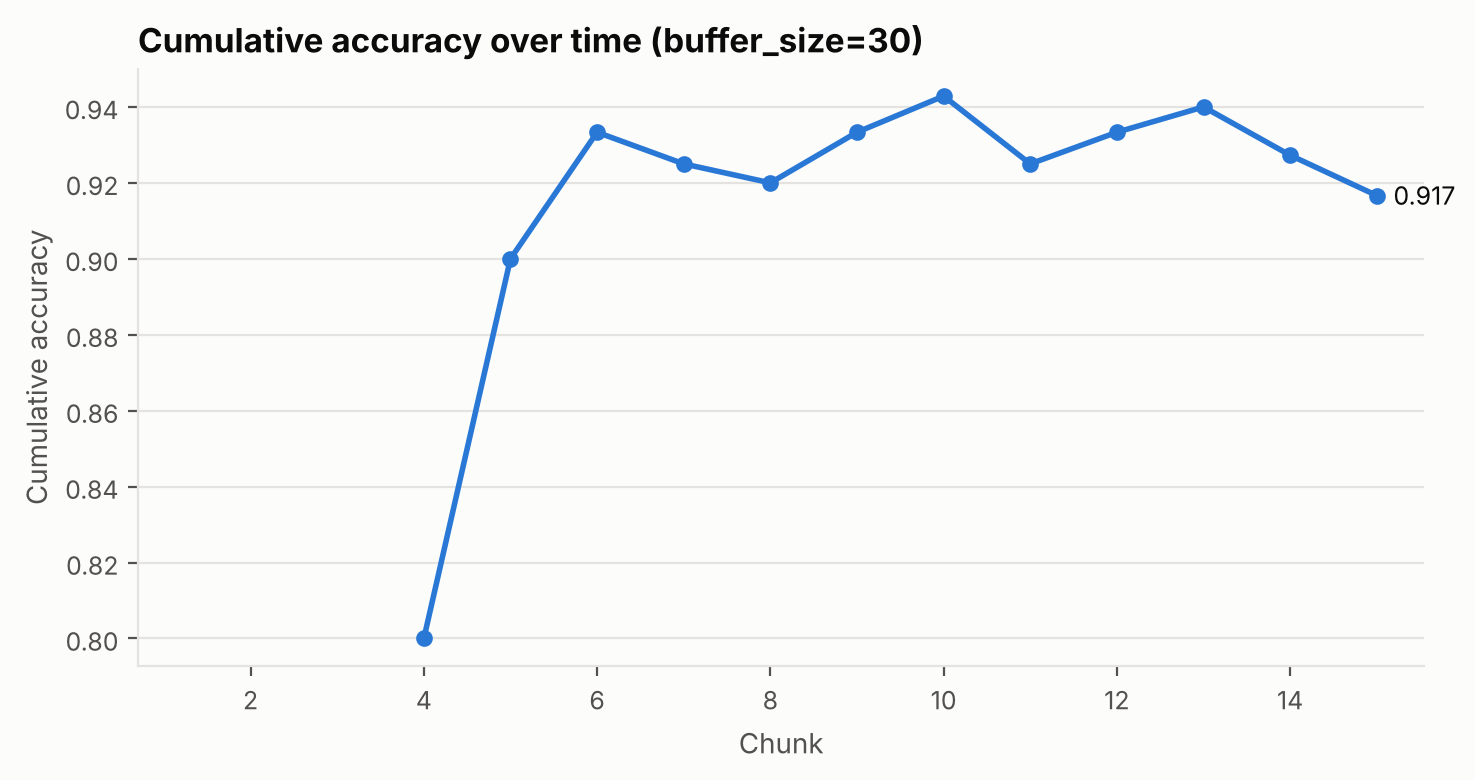

In [8]:
visualise.plot_metric_over_time(
    trainer.get_metric("cumulative_accuracy"),
    title="Cumulative accuracy over time (buffer_size=30)", ylabel="Cumulative accuracy");

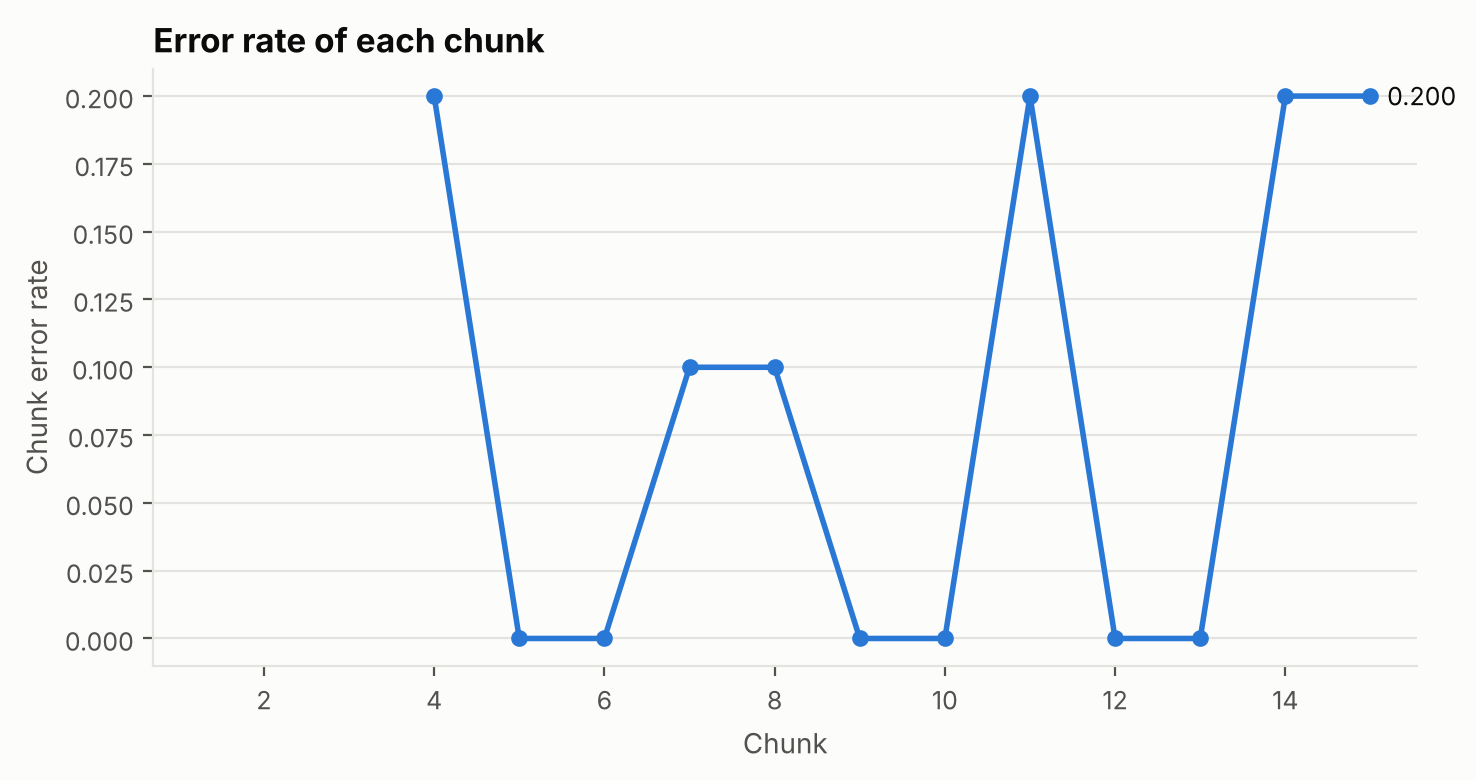

In [9]:
visualise.plot_metric_over_time(
    trainer.get_metric("error"), title="Error rate of each chunk", ylabel="Chunk error rate");

### Model comparison: two buffer sizes

`compare_models` puts two models on the same axis. A larger buffer retrains less often on more data:
it starts predicting later, but each tree has seen more examples.

buffer_size=30   retrains=5  cumulative accuracy=0.917  total fit=5.21 ms  peak memory=2.5 KiB
buffer_size=60   retrains=2  cumulative accuracy=0.922  total fit=3.36 ms  peak memory=4.5 KiB


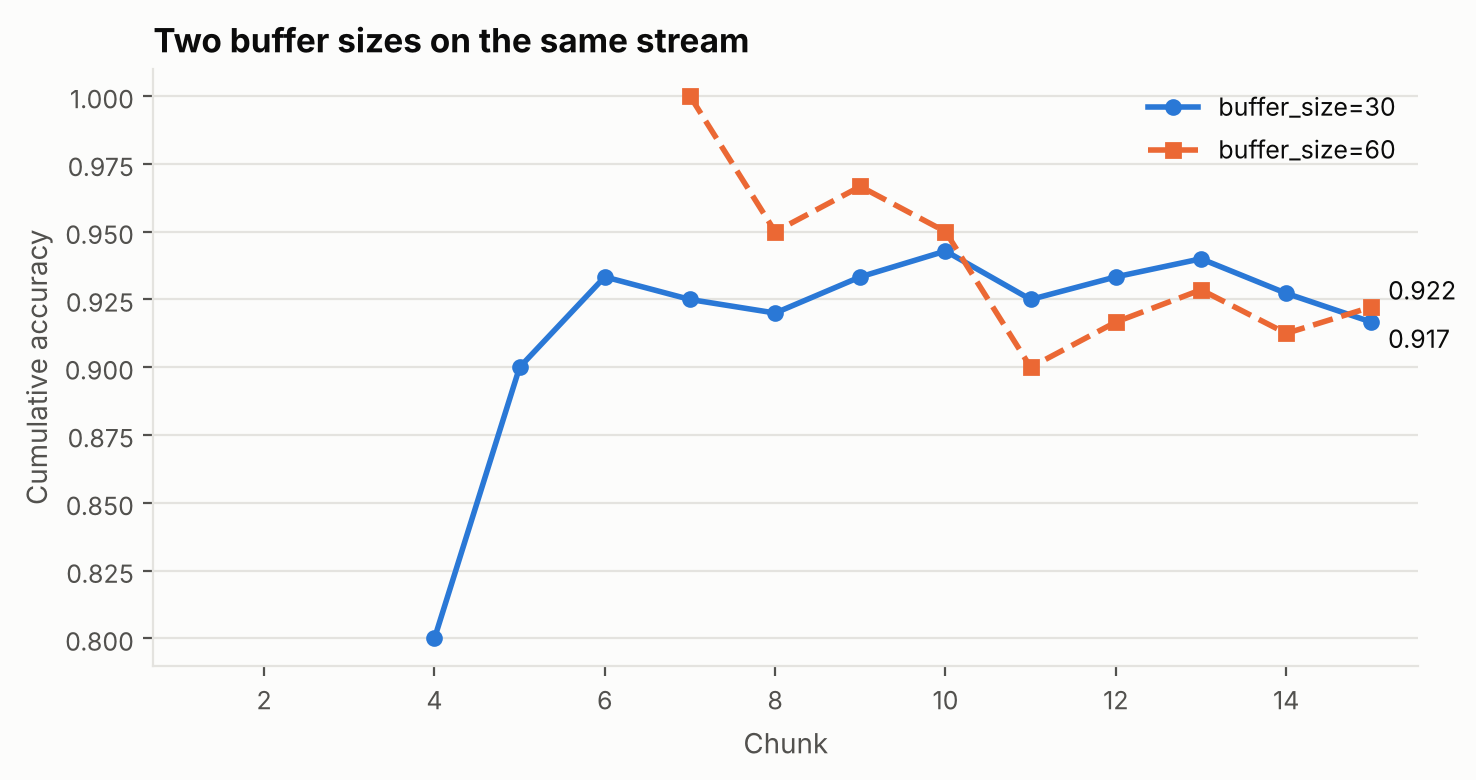

In [10]:
other = StreamTrainer(make_pipeline(buffer_size=60), window=50, name="buffer_size=60")
other.run(stream())

for run in (trainer, other):
    s = run.summary()
    print(f"{run.name:<16} retrains={s['n_retrains']}  cumulative accuracy={s['cumulative_accuracy']:.3f}  "
          f"total fit={s['total_fit_seconds'] * 1e3:.2f} ms  peak memory={s['peak_memory_bytes'] / 1024:.1f} KiB")

visualise.compare_models(
    trainer.get_metric("cumulative_accuracy"), other.get_metric("cumulative_accuracy"),
    labels=(trainer.name, other.name),
    title="Two buffer sizes on the same stream", ylabel="Cumulative accuracy");

### Predictions vs ground truth on the latest chunk

An open circle is the true class, a filled dot a correct prediction, a red cross a wrong one.

true     : ['versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'virginica', 'versicolor', 'setosa', 'setosa', 'versicolor']
predicted: ['versicolor', 'virginica', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'setosa', 'setosa', 'versicolor']


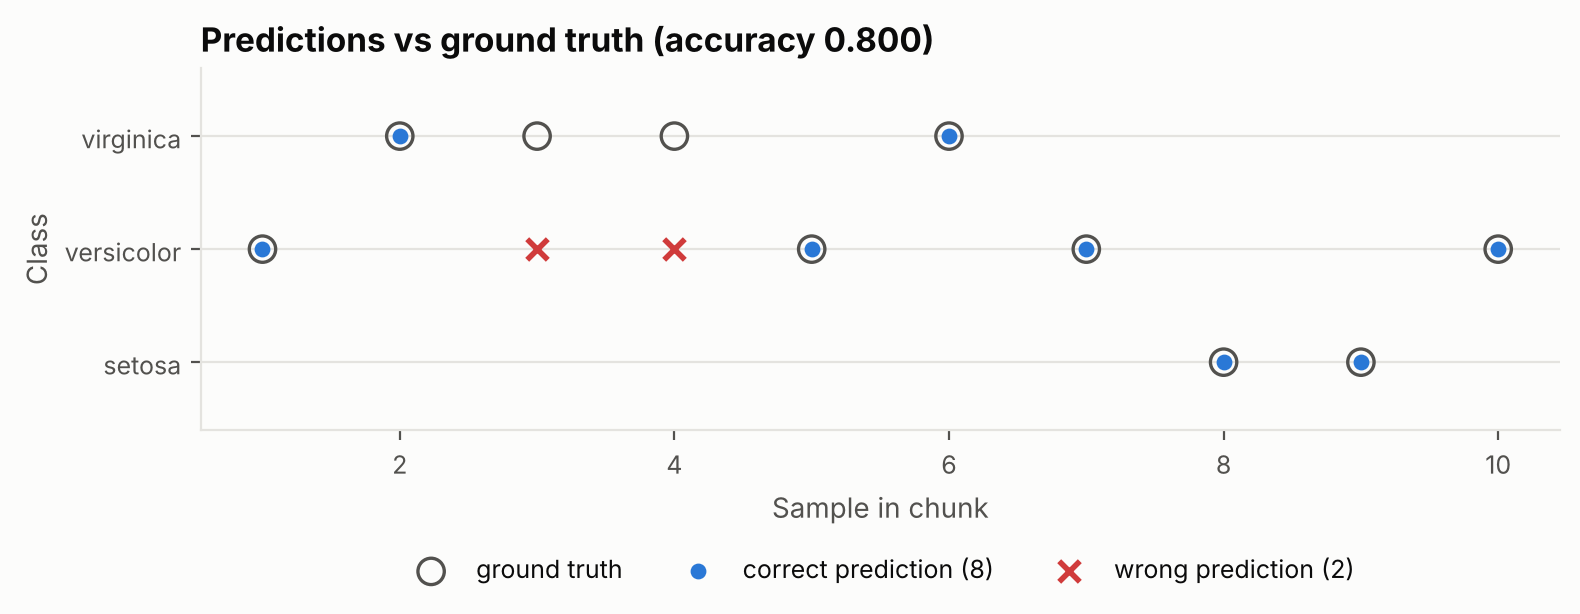

In [11]:
print("true     :", trainer.last_y_true_.tolist())
print("predicted:", trainer.last_y_pred_.tolist())
visualise.plot_predictions_vs_ground_truth(trainer.last_y_true_, trainer.last_y_pred_);

### Saving instead of showing

Every plotting function takes `save_path=` and `show=False`, for scripts and pipeline logs.
The chunk log itself can be written to CSV.

In [12]:
OUT = os.path.join(ROOT, "demo", "outputs")
fig, ax = visualise.plot_metric_over_time(
    trainer.get_metric("rolling_accuracy"), "Rolling accuracy (last 50 samples)", "Rolling accuracy",
    save_path=os.path.join(OUT, "notebook_rolling_accuracy.png"), show=False)
matplotlib.pyplot.close(fig)
log_file = trainer.save_log(os.path.join(OUT, "notebook_stream_log.csv"))
print("saved:", sorted(f for f in os.listdir(OUT) if f.startswith("notebook_")))

saved: ['notebook_rolling_accuracy.png', 'notebook_stream_log.csv']


## 5. Reading the file itself as a stream

The chunks above came from an array in memory. `io.iter_csv` reads the CSV a few lines at a time, so a
file larger than memory can feed the same streaming components. Here the running statistics and a
streaming histogram are updated straight from the file.

In [13]:
running = stats.RunningStats()
hist = stats.StreamingHistogram(bins=6, range=(1.0, 7.0))        # petal length
for chunk, cols in io.iter_csv(DATA, chunk_size=40, header=True, usecols=(0, 1, 2, 3)):
    running.update_stats(chunk)
    hist.update(chunk[:, 2])
    print(f"read {chunk.shape[0]:>2} rows -> mean so far {np.round(running.mean(), 3)}")

counts, edges = hist.result()
print("\npetal_length histogram from the stream:")
print(stats.format_histogram(counts, edges))

read 40 rows -> mean so far [5.038 3.453 1.46  0.235]
read 40 rows -> mean so far [5.405 3.189 2.539 0.661]
read 40 rows -> mean so far [5.652 3.069 3.327 0.996]
read 30 rows -> mean so far [5.843 3.057 3.758 1.199]

petal_length histogram from the stream:
[   1.000,    2.000) | ######################################## 50
[   2.000,    3.000) |  0
[   3.000,    4.000) | ######### 11
[   4.000,    5.000) | ################################## 43
[   5.000,    6.000) | ############################ 35
[   6.000,    7.000] | ######### 11


## 6. Benchmarks (small versions)

The full benchmarks are in `benchmark/` (`python benchmark/stream_benchmarks.py`), with their results
saved in `benchmark/results/`. Two small ones are repeated here so their output stays in the notebook.

**(a) Loop vs vectorised.** The tree's split search scores every feature and threshold of a node. The
loop version tries them one by one; the vectorised version uses one sort and one cumulative sum.

In [14]:
import time
sys.path.insert(0, os.path.join(ROOT, "benchmark"))
from stream_benchmarks import loop_best_split, make_classification, make_drift_stream
from numcompute_stream.tree import _best_split

def median_ms(fn, repeat=5):
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return float(np.median(times)) * 1e3

print(f"{'rows':>6} {'loop (ms)':>11} {'vectorised (ms)':>16} {'speed-up':>9}  same result")
for n in (200, 1000, 2000):
    Xb, yb = make_classification(n, 8, np.random.default_rng(0))
    Xl, yl = Xb.tolist(), yb.tolist()
    a, b = loop_best_split(Xl, yl, 3), _best_split(Xb, yb, 3)
    same = a[0] == b[0] and np.isclose(a[1], b[1]) and np.isclose(a[2], b[2])
    t_loop, t_vec = median_ms(lambda: loop_best_split(Xl, yl, 3)), median_ms(lambda: _best_split(Xb, yb, 3))
    print(f"{n:>6} {t_loop:>11.2f} {t_vec:>16.3f} {t_loop / t_vec:>8.1f}x  {same}")

  rows   loop (ms)  vectorised (ms)  speed-up  same result


   200       10.36            0.294     35.3x  True


  1000       58.02            1.272     45.6x  True


  2000      145.17            2.181     66.5x  True


**(b) Buffer size.** One stream of 12,000 samples whose labelling rule changes half way (concept drift).
Small buffers retrain often and recover quickly after the change; large buffers build better trees on a
stable stream but each retrain costs more and they are slow to notice the change.

buffer_size  retrains  accuracy  before drift  after drift  mean retrain (ms)
        100       120     0.898         0.901        0.895               1.28


        500        24     0.900         0.931        0.873               6.89
       2000         6     0.811         0.949        0.718              23.59


       4000         3     0.581         0.950        0.457              51.21


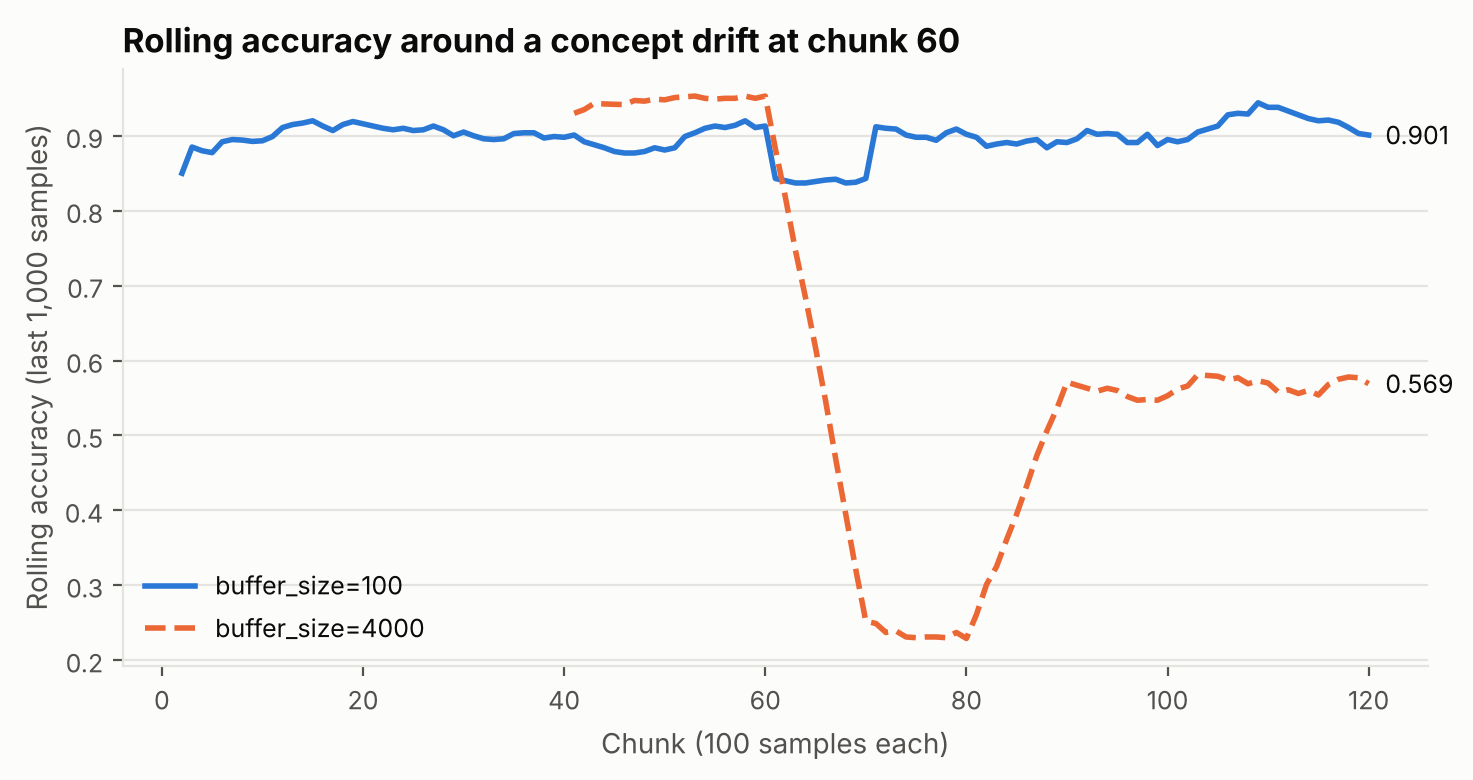

In [15]:
Xs, ys = make_drift_stream(12000, np.random.default_rng(0))
runs = {}
print(f"{'buffer_size':>11} {'retrains':>9} {'accuracy':>9} {'before drift':>13} {'after drift':>12} "
      f"{'mean retrain (ms)':>18}")
for size in (100, 500, 2000, 4000):
    run = StreamTrainer(DecisionTreeClassifier(max_depth=6, buffer_size=size), window=1000,
                        name=f"buffer_size={size}")
    run.run(iter_chunks(Xs, ys, chunk_size=100))
    acc, fit = run.get_metric("chunk_accuracy"), run.get_metric("fit_seconds")
    retrained = np.array([r["retrained"] for r in run.history])
    runs[size] = run
    print(f"{size:>11} {run.summary()['n_retrains']:>9} {run.summary()['cumulative_accuracy']:>9.3f} "
          f"{np.nanmean(acc[:60]):>13.3f} {np.nanmean(acc[60:]):>12.3f} {fit[retrained].mean() * 1e3:>18.2f}")

visualise.compare_models(
    runs[100].get_metric("rolling_accuracy"), runs[4000].get_metric("rolling_accuracy"),
    labels=("buffer_size=100", "buffer_size=4000"),
    title="Rolling accuracy around a concept drift at chunk 60",
    ylabel="Rolling accuracy (last 1,000 samples)", xlabel="Chunk (100 samples each)");

## Summary

- `io.py` loaded the CSV, both whole and in chunks.
- `stats.update_stats`, `RunningStats`, `StreamingHistogram` kept statistics without storing the stream.
- `Pipeline.partial_fit` updated the imputer, the scaler and the buffered decision tree chunk by chunk.
- `StreamTrainer` logged per-chunk accuracy, cumulative accuracy, timing and memory.
- `visualise.py` drew the metric curves, the model comparison and predictions against ground truth.

To check the whole framework from a terminal run `python demo/iris_demo.py`, and for the tests `pytest`.